In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

train_path = "/content/drive/MyDrive/split_dataset/train"
test_path = "/content/drive/MyDrive/split_dataset/test"

# Get class folders directly from directories
train_classes = sorted([d for d in os.listdir(train_path) if os.path.isdir(os.path.join(train_path, d))])
test_classes = sorted([d for d in os.listdir(test_path) if os.path.isdir(os.path.join(test_path, d))])

# Only use common classes
common_classes = sorted(list(set(train_classes) & set(test_classes)))

# Safely get class counts
def get_class_counts(data_path, class_list):
    counts = {}
    for cls in class_list:
        folder = os.path.join(data_path, cls)
        if os.path.exists(folder):
            counts[cls] = len(os.listdir(folder))
        else:
            print(f"⚠️ Warning: Folder not found for class {cls} in {data_path}")
            counts[cls] = 0
    return counts

train_counts = get_class_counts(train_path, common_classes)
test_counts = get_class_counts(test_path, common_classes)

# Plot class distribution
plt.figure(figsize=(14, 6))
x = np.arange(len(common_classes))
width = 0.35

plt.bar(x - width/2, [train_counts[c] for c in common_classes], width, label='Train')
plt.bar(x + width/2, [test_counts[c] for c in common_classes], width, label='Test')
plt.xticks(ticks=x, labels=common_classes, rotation=90)
plt.title("Pest Class Distribution in Train and Test")
plt.xlabel("Pest Classes")
plt.ylabel("Number of Images")
plt.legend()
plt.tight_layout()
plt.show()

# Sample images from train
fig, axes = plt.subplots(3, 5, figsize=(15, 10))
axes = axes.flatten()
for i, cls in enumerate(common_classes[:15]):
    img_path = os.path.join(train_path, cls, os.listdir(os.path.join(train_path, cls))[0])
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[i].imshow(img)
    axes[i].set_title(cls)
    axes[i].axis("off")
plt.suptitle("Sample Images from Train Classes")
plt.tight_layout()
plt.show()

# Image shape check
img_shapes = []
for cls in common_classes:
    cls_path = os.path.join(train_path, cls)
    for img_name in os.listdir(cls_path)[:5]:
        img = cv2.imread(os.path.join(cls_path, img_name))
        if img is not None:
            img_shapes.append(img.shape)

unique_shapes = np.unique(img_shapes, axis=0)
print("Unique Image Shapes (sampled):", unique_shapes)

# PCA on flattened grayscale images
def extract_features(data_path, classes, img_size=(64, 64), max_per_class=50):
    features, labels = [], []
    for cls in classes:
        cls_folder = os.path.join(data_path, cls)
        if not os.path.exists(cls_folder): continue
        for img_name in os.listdir(cls_folder)[:max_per_class]:
            img_path = os.path.join(cls_folder, img_name)
            img = cv2.imread(img_path)
            if img is not None:
                img = cv2.resize(img, img_size)
                img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
                features.append(img.flatten())
                labels.append(cls)
    return np.array(features), labels

features, labels = extract_features(train_path, common_classes, max_per_class=100)

scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

pca = PCA(n_components=2)
pca_result = pca.fit_transform(features_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=pca_result[:, 0], y=pca_result[:, 1], hue=labels, palette='tab20', s=30, legend='full')
plt.title("PCA of Train Image Features (2D Projection)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "<ipython-input-2-2f8ab6f2b0c6>", line 3, in <cell line: 0>
    import seaborn as sns
  File "/usr/local/lib/python3.11/dist-packages/seaborn/__init__.py", line 5, in <module>
    from .relational import *  # noqa: F401,F403
    ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/seaborn/relational.py", line 21, in <module>
    from ._statistics import EstimateAggregator, WeightedAggregator
  File "/usr/local/lib/python3.11/dist-packages/seaborn/_statistics.py", line 32, in <module>
    from scipy.stats import gaussian_kde
  File "/usr/local/lib/python3.11/dist-packages/scipy/stats/__init__.py", line 652, in <module>
    from ._new_distributions import Normal, Uniform
  File "/usr/local/lib/python3.11/dist-packages/scipy/stats/_new_distributions.py", line 375, in <m

TypeError: object of type 'NoneType' has no len()

/usr/local/lib/python3.11/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


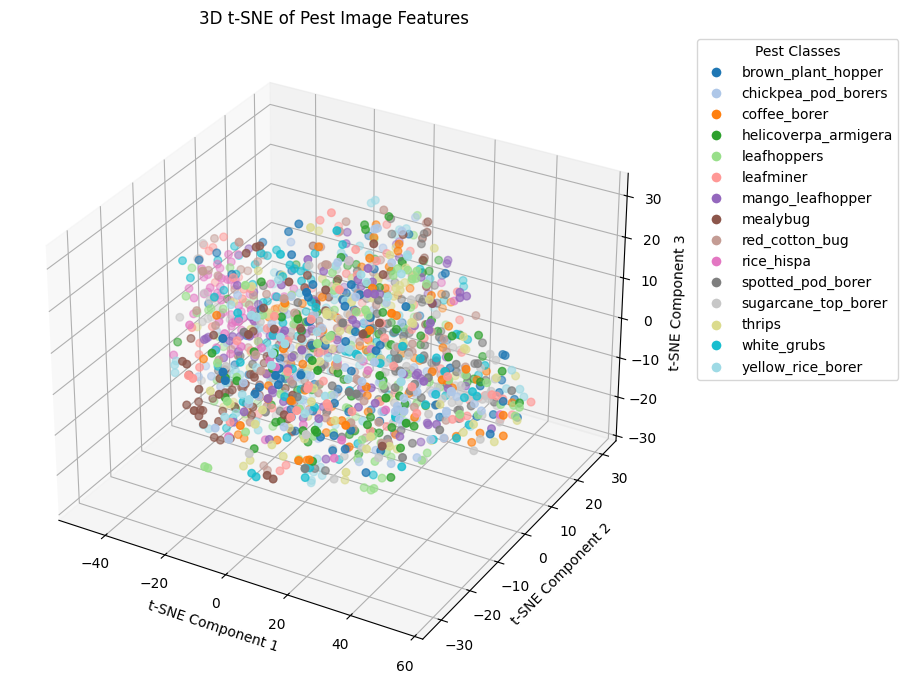

In [ ]:
import pandas as pd
from sklearn.manifold import TSNE
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

# Convert labels list to Pandas Series
labels_series = pd.Series(labels)

# Run 3D t-SNE
tsne_3d = TSNE(n_components=3, perplexity=30, n_iter=1000, random_state=42)
tsne_result_3d = tsne_3d.fit_transform(features_scaled)

# Plotting 3D t-SNE
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(tsne_result_3d[:, 0], tsne_result_3d[:, 1], tsne_result_3d[:, 2],
                     c=labels_series.astype('category').cat.codes, cmap='tab20', s=30)

# Customizing plot
ax.set_title("3D t-SNE of Pest Image Features")
ax.set_xlabel("t-SNE Component 1")
ax.set_ylabel("t-SNE Component 2")
ax.set_zlabel("t-SNE Component 3")

# Legend
legend_labels = labels_series.unique()
legend_colors = scatter.cmap(scatter.norm(range(len(legend_labels))))
legend_handles = [plt.Line2D([0], [0], marker='o', color='w',
                             label=label,
                             markerfacecolor=legend_colors[i], markersize=8)
                  for i, label in enumerate(legend_labels)]

ax.legend(handles=legend_handles, bbox_to_anchor=(1.05, 1), loc='upper left', title="Pest Classes")
plt.tight_layout()
plt.show()


In [ ]:
import os
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB3
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau
from google.colab import drive

# 🔹 Mount Google Drive
drive.mount('/content/drive')

# 🔹 Corrected dataset paths
dataset_path = "/content/drive/MyDrive/split_dataset"
train_path = os.path.join(dataset_path, "train")
test_path = os.path.join(dataset_path, "test")

# 🔹 Image parameters
img_size = (224, 224)
batch_size = 32

# 🔹 Data Augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=45,
    width_shift_range=0.3,
    height_shift_range=0.3,
    shear_range=0.3,
    zoom_range=0.4,
    brightness_range=[0.7, 1.3],
    channel_shift_range=25.0,
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode='nearest'
)

test_datagen = ImageDataGenerator(rescale=1./255)

# 🔹 Load dataset
train_generator = train_datagen.flow_from_directory(
    train_path, target_size=img_size, batch_size=batch_size, class_mode='categorical'
)
test_generator = test_datagen.flow_from_directory(
    test_path, target_size=img_size, batch_size=batch_size, class_mode='categorical', shuffle=False
)

# 🔹 Get the correct number of classes
num_classes = len(train_generator.class_indices)
print(f"✅ Detected {num_classes} classes.")  # Should print 16 if dataset is structured correctly

# 🔹 Load EfficientNetB3
base_model = EfficientNetB3(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# 🔹 Fine-Tune More Layers
for layer in base_model.layers[:60]:
    layer.trainable = False
for layer in base_model.layers[60:]:
    layer.trainable = True

# 🔹 Build the Model
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dense(128, activation='relu')(x)
x = Dense(num_classes, activation='softmax')(x)  # 🔹 Fix: Ensure correct class count
model = Model(inputs=base_model.input, outputs=x)

# 🔹 Compile Model with Label Smoothing
optimizer = Adam(learning_rate=1e-4)
model.compile(optimizer=optimizer, loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1), metrics=['accuracy'])

# 🔹 Reduce Learning Rate when Validation Loss Stops Improving
lr_scheduler = ReduceLROnPlateau(monitor='val_loss', patience=3, factor=0.5, verbose=1, min_lr=1e-6)

# 🔹 Train Model (First Phase)
epochs = 15
model.fit(
    train_generator,
    validation_data=test_generator,
    epochs=epochs,
    callbacks=[lr_scheduler]
)

# 🔹 Fine-Tune with Lower Learning Rate
optimizer_finetune = Adam(learning_rate=1e-5)
model.compile(optimizer=optimizer_finetune, loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1), metrics=['accuracy'])

# 🔹 Train Model (Fine-Tuning Phase)
epochs_finetune = 10
model.fit(
    train_generator,
    validation_data=test_generator,
    epochs=epochs_finetune,
    callbacks=[lr_scheduler]
)

# 🔹 Evaluate Model
test_loss, test_acc = model.evaluate(test_generator)
print(f"🚀 Final Test Accuracy: {test_acc * 100:.2f}%")

# 🔹 Save Model
model_save_path = "/content/drive/MyDrive/pest_model_optimized.keras"
model.save(model_save_path)
print(f"✅ Training complete! Model saved at: {model_save_path}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/split_dataset/train'

1/1 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step


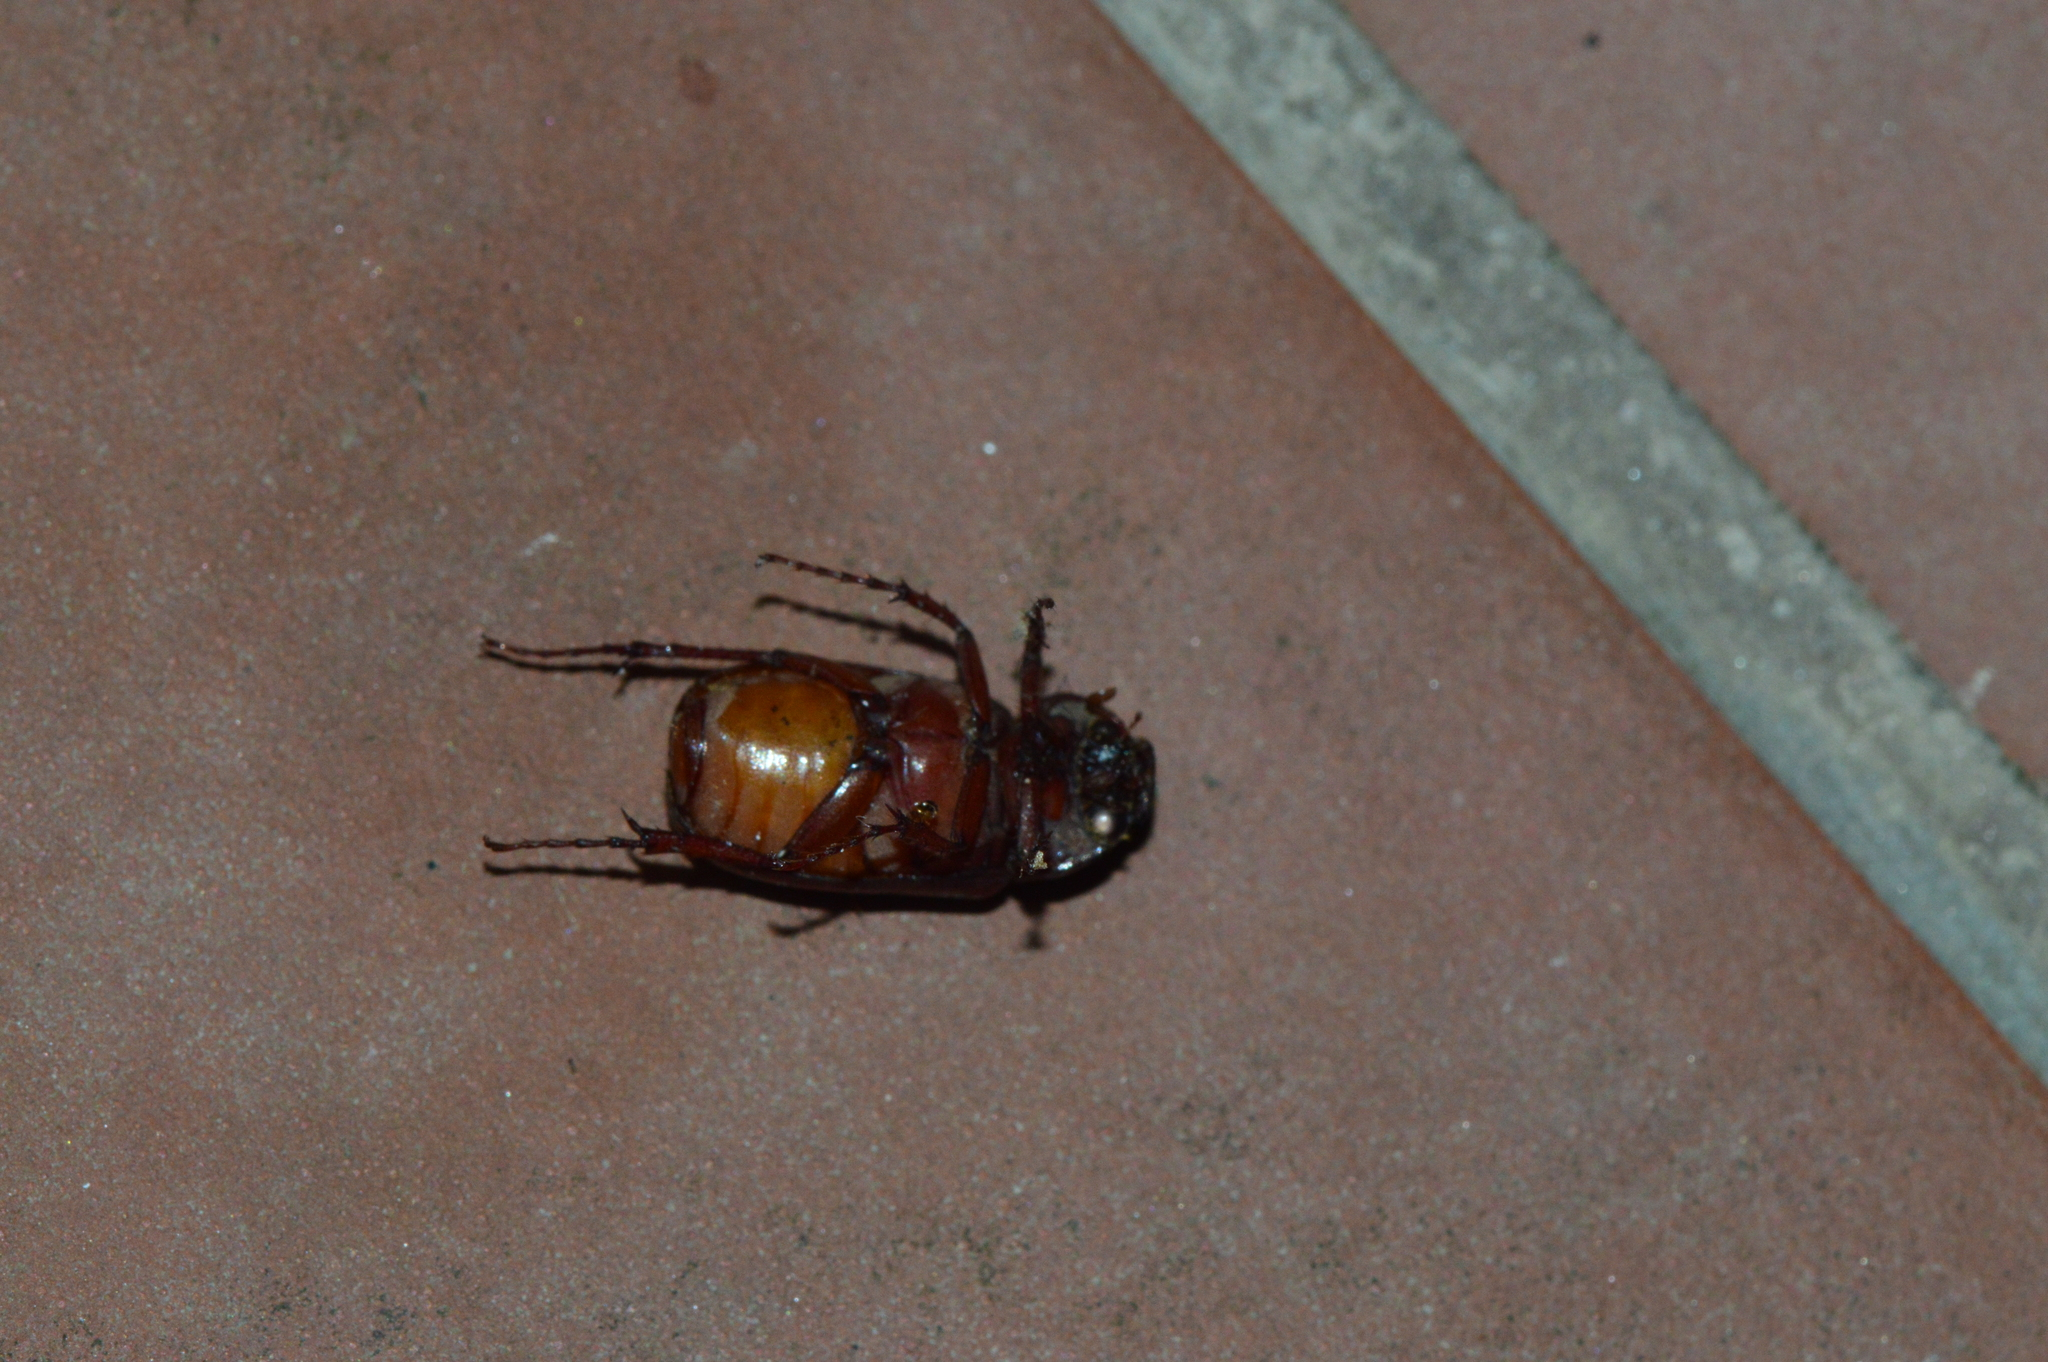

Pest Identified: white_grubs with 82.14% confidence


In [3]:
import tensorflow as tf
import numpy as np
import cv2
import os
from google.colab.patches import cv2_imshow  # For displaying images in Colab
from tensorflow.keras.preprocessing import image
# Step 2: Load the trained model (Update the path based on your Drive location)
model_path = "/content/drive/MyDrive/pest_model_optimized.keras"  # Change to your actual path
model = tf.keras.models.load_model(model_path)
# Step 3: Define pest class labels (Update these with your actual class names)
class_labels = ['brown_ plant_hopper', 'chickpea_pod_borers', 'coffee_borer', 'diamondback_moth', 'helicoverpa_armigera','leafhoppers', 'leafminer', 'mango_leafhopper', 'mealybug','red_cotton_bug', 'rice_hispa', 'rice_hispa','sugarcane_top_borer', 'thrips', 'white_grubs', 'white_grubs']  # Modify as needed
def preprocess_image(image_path, target_size=(224, 224)):
    """Load and preprocess the image for prediction"""
    img = image.load_img(image_path, target_size=target_size)  # Load and resize
    img = image.img_to_array(img) / 255.0  # Convert to array & normalize
    img = np.expand_dims(img, axis=0)  # Add batch dimension
    return img
def predict_pest(image_path):
    """Predict the pest class from an image"""
    img = preprocess_image(image_path)
    prediction = model.predict(img)
    class_idx = np.argmax(prediction)  # Get index of highest confidence
    class_name = class_labels[class_idx]  # Get corresponding class label
    confidence = prediction[0][class_idx] * 100
    # Display the image
    img_cv = cv2.imread(image_path)
    cv2_imshow(img_cv)
    return class_name, confidence
# Step 4: Provide image path from Google Drive
image_path = "/content/drive/MyDrive/split_dataset/test/white_grubs/White Grubs_021.jpg"  # Change to actual image path
# Step 5: Perform prediction
pest_name, confidence = predict_pest(image_path)
print(f"Pest Identified: {pest_name} with {confidence:.2f}% confidence")

In [4]:
import numpy as np
import tensorflow as tf
import cv2
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

def preprocess_image_for_gradcam(img_path, target_size=(224, 224)):
    """Preprocess the image for EfficientNet."""
    img = image.load_img(img_path, target_size=target_size)
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    return img_array

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    """Generates the Grad-CAM heatmap."""
    grad_model = tf.keras.models.Model(
        [model.inputs], [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        output_class = predictions[:, pred_index]

    # Gradients of output class w.r.t. last conv layer
    grads = tape.gradient(output_class, conv_outputs)

    # Mean intensity of gradients for each channel
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Multiply each channel by "how important" it is
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normalize the heatmap
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

def display_gradcam(image_path, model, last_conv_layer_name='top_conv', alpha=0.4):
    """Displays the Grad-CAM heatmap on the original image."""
    img_array = preprocess_image_for_gradcam(image_path)
    heatmap = make_gradcam_heatmap(img_array, model, last_conv_layer_name)

    # Load original image (for overlay)
    img = cv2.imread(image_path)
    img = cv2.resize(img, (224, 224))
    heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))

    # Convert to heatmap color
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
    superimposed_img = cv2.addWeighted(img, 1 - alpha, heatmap_colored, alpha, 0)

    print("🔍 Grad-CAM Visualization:")
    cv2_imshow(superimposed_img)


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_layer']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


🔍 Grad-CAM Visualization:


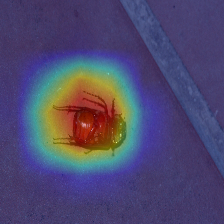

In [5]:
# For EfficientNet, the final conv layer is usually 'top_conv'
display_gradcam(image_path, model, last_conv_layer_name='top_conv')


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from imblearn.over_sampling import SMOTE
import joblib
import tensorflow as tf
from tensorflow.keras.preprocessing import image

# Load dataset
df = pd.read_csv('/content/drive/MyDrive/Sustainable_Pest_Control_Cleaned.csv')
df.ffill(inplace=True)  # updated based on warning

# Label encode
encoders = {}
for col in ['pest_name', 'crop_type', 'growth_stage', 'location', 'soil_type', 'sustainable_control_method']:
    encoders[col] = LabelEncoder()
    df[col] = encoders[col].fit_transform(df[col])

# Define features and targets
features = df.drop(['pest_name', 'infestation_severity', 'sustainable_control_method'], axis=1)
target_soil = df['soil_type']
target_severity = df['infestation_severity']
target_control = df['sustainable_control_method']

# Train/test split
X_train, X_test, y_train_soil, y_test_soil, y_train_severity, y_test_severity, y_train_control, y_test_control = train_test_split(
    features, target_soil, target_severity, target_control, test_size=0.2, random_state=42)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Save feature names for prediction alignment later
feature_columns = X_train.columns.tolist()

# Handle SMOTE for each target
smote = SMOTE(random_state=42, k_neighbors=2)

# Sustainable control method
class_counts = y_train_control.value_counts()
valid_classes = class_counts[class_counts > 1].index.tolist()
mask = y_train_control.isin(valid_classes)
X_resampled_control, y_resampled_control = smote.fit_resample(X_train_scaled[mask], y_train_control[mask])

# Soil and severity models
X_resampled_soil, y_resampled_soil = smote.fit_resample(X_train_scaled, y_train_soil)
X_resampled_severity, y_resampled_severity = smote.fit_resample(X_train_scaled, y_train_severity)

# Train models
soil_model = RandomForestClassifier(random_state=42).fit(X_resampled_soil, y_resampled_soil)
severity_model = RandomForestRegressor(random_state=42).fit(X_resampled_severity, y_resampled_severity)
control_model = RandomForestClassifier(random_state=42).fit(X_resampled_control, y_resampled_control)

# Save everything
joblib.dump(soil_model, '/content/soil_model.pkl')
joblib.dump(severity_model, '/content/severity_model.pkl')
joblib.dump(control_model, '/content/control_model.pkl')
joblib.dump(scaler, '/content/scaler.pkl')
joblib.dump(encoders, '/content/encoders.pkl')
joblib.dump(feature_columns, '/content/feature_columns.pkl')

# Load pest classification model
pest_model = tf.keras.models.load_model('/content/drive/MyDrive/pest_model_optimized.keras')

# Prediction function
def predict_pest_and_other_factors(image_path):
    # Load encoders and scaler
    encoders = joblib.load('/content/encoders.pkl')
    scaler = joblib.load('/content/scaler.pkl')
    feature_columns = joblib.load('/content/feature_columns.pkl')

    # Load image and predict pest
    img = image.load_img(image_path, target_size=(224, 224))
    img_array = np.expand_dims(image.img_to_array(img) / 255.0, axis=0)

    pest_prediction = pest_model.predict(img_array)
    pest_class = np.argmax(pest_prediction, axis=1)[0]
    pest_name = encoders['pest_name'].inverse_transform([pest_class])[0]

    print(f"Pest identified: {pest_name}")

    # Get matching row (first sample of predicted pest)
    pest_row = df[df['pest_name'] == pest_class].iloc[0]

    # Extract features
    X_input = pest_row[feature_columns].values.reshape(1, -1)
    X_input_scaled = scaler.transform(X_input)

    # Load models
    soil_model = joblib.load('/content/soil_model.pkl')
    severity_model = joblib.load('/content/severity_model.pkl')
    control_model = joblib.load('/content/control_model.pkl')

    # Make predictions
    soil_pred = soil_model.predict(X_input_scaled)[0]
    severity_pred = severity_model.predict(X_input_scaled)[0]
    control_pred = control_model.predict(X_input_scaled)[0]

    # Decode predictions
    soil_label = encoders['soil_type'].inverse_transform([soil_pred])[0]
    control_label = encoders['sustainable_control_method'].inverse_transform([control_pred])[0]

    print(f"Predicted Soil Type: {soil_label}")
    print(f"Predicted Infestation Severity: {severity_pred}")
    print(f"Predicted Sustainable Control Method: {control_label}")

    return {
        "pest_name": pest_name,
        "soil_type": soil_label,
        "infestation_severity": severity_pred,
        "sustainable_control_method": control_label
    }

# Run prediction
image_path = '/content/drive/MyDrive/split_dataset/test/red_cotton_bug/Dysdercus_koenigii_016.jpg'
predictions = predict_pest_and_other_factors(image_path)
print(predictions)



🟢 Soil Type Classification Report:
              precision    recall  f1-score   support

    Alluvial       1.00      1.00      1.00        24
  Black Soil       1.00      1.00      1.00        35
    Laterite       1.00      1.00      1.00        30
       Loamy       1.00      1.00      1.00        18
    Red Soil       0.93      1.00      0.96        27
       Sandy       1.00      0.67      0.80         6

    accuracy                           0.99       140
   macro avg       0.99      0.94      0.96       140
weighted avg       0.99      0.99      0.98       140



<ipython-input-5-f4605b38d150>:31: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128994 (\N{LARGE GREEN CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


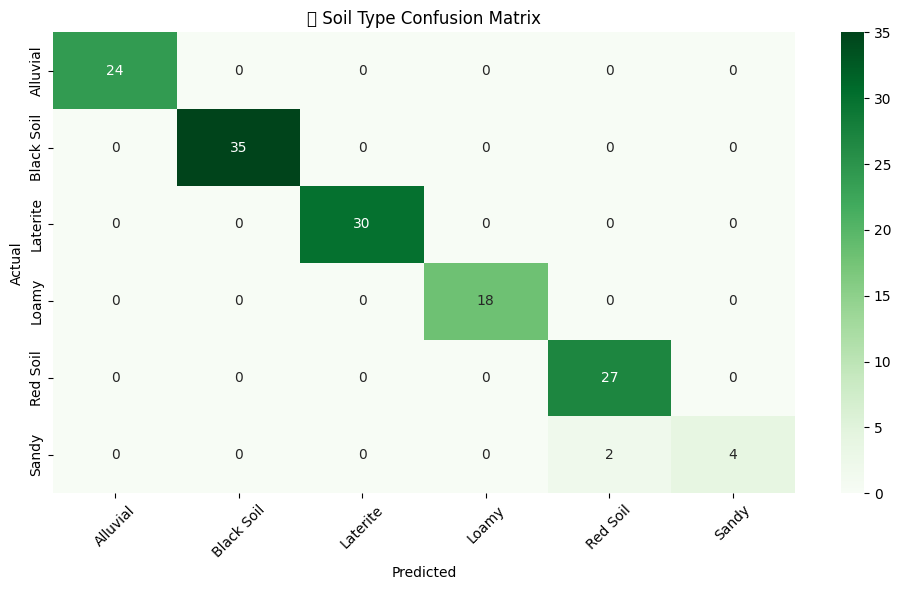

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_


🔵 Infestation Severity Regression Report:
MAE: 9.26
MSE: 114.63
RMSE: 10.71
R² Score: -0.08

🟣 Sustainable Control Method Classification Report:
                                                                 precision    recall  f1-score   support

                           Adoption of Resistant Crop Varieties       0.00      0.00      0.00         8
                   Biopesticides (e.g., Bacillus thuringiensis)       0.00      0.00      0.00         6
         Companion Planting (e.g., Marigold for pest repulsion)       0.16      0.23      0.19        13
                                           Compost Tea Spraying       0.00      0.00      0.00         9
                                                  Crop Rotation       0.00      0.00      0.00         9
                                 Diatomaceous Earth Application       0.20      0.10      0.13        10
                                             Garlic-Chili Spray       0.00      0.00      0.00         8
             

<ipython-input-5-f4605b38d150>:59: UserWarning: Glyph 128995 (\N{LARGE PURPLE CIRCLE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128995 (\N{LARGE PURPLE CIRCLE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


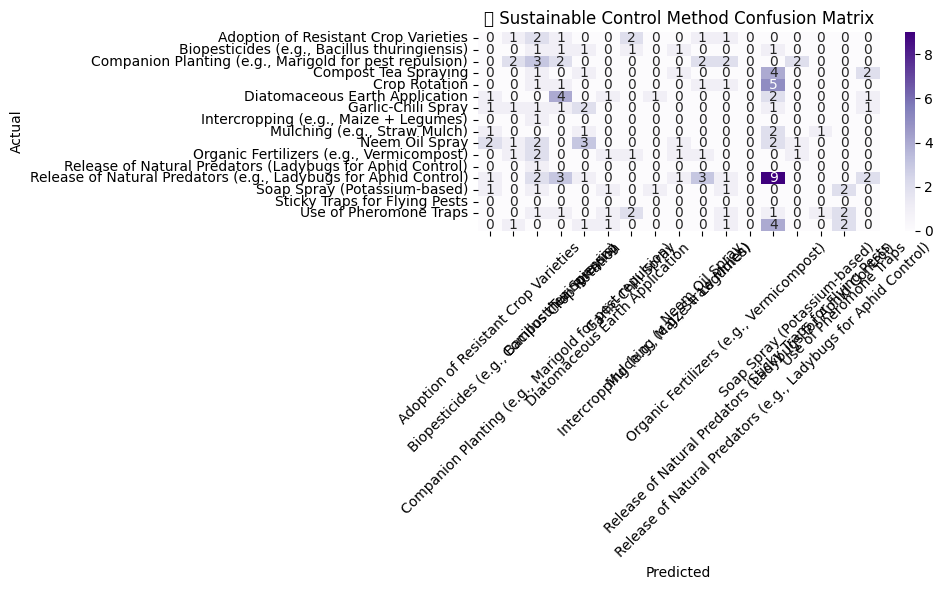

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

# Load encoders, models, and scaler
encoders = joblib.load('/content/encoders.pkl')
scaler = joblib.load('/content/scaler.pkl')
soil_model = joblib.load('/content/soil_model.pkl')
severity_model = joblib.load('/content/severity_model.pkl')
control_model = joblib.load('/content/control_model.pkl')

# Scale test data
X_test_scaled = scaler.transform(X_test)

### --- 1. Soil Type Classification Evaluation ---
soil_preds = soil_model.predict(X_test_scaled)
true_soil_labels = encoders['soil_type'].inverse_transform(y_test_soil)
pred_soil_labels = encoders['soil_type'].inverse_transform(soil_preds)

print("\n🟢 Soil Type Classification Report:")
print(classification_report(true_soil_labels, pred_soil_labels))

# Confusion Matrix
plt.figure(figsize=(10, 6))
sns.heatmap(confusion_matrix(true_soil_labels, pred_soil_labels), annot=True, fmt='d',
            xticklabels=np.unique(true_soil_labels), yticklabels=np.unique(true_soil_labels), cmap='Greens')
plt.title("🟢 Soil Type Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### --- 2. Infestation Severity Regression Evaluation ---
severity_preds = severity_model.predict(X_test_scaled)

print("\n🔵 Infestation Severity Regression Report:")
print(f"MAE: {mean_absolute_error(y_test_severity, severity_preds):.2f}")
print(f"MSE: {mean_squared_error(y_test_severity, severity_preds):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_severity, severity_preds)):.2f}")
print(f"R² Score: {r2_score(y_test_severity, severity_preds):.2f}")

### --- 3. Sustainable Control Method Classification Evaluation ---
control_preds = control_model.predict(X_test_scaled)
true_control_labels = encoders['sustainable_control_method'].inverse_transform(y_test_control)
pred_control_labels = encoders['sustainable_control_method'].inverse_transform(control_preds)

print("\n🟣 Sustainable Control Method Classification Report:")
print(classification_report(true_control_labels, pred_control_labels))

# Confusion Matrix
plt.figure(figsize=(10, 6))
sns.heatmap(confusion_matrix(true_control_labels, pred_control_labels), annot=True, fmt='d',
            xticklabels=np.unique(true_control_labels), yticklabels=np.unique(true_control_labels), cmap='Purples')
plt.title("🟣 Sustainable Control Method Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
# Step 1: Install Gradio & Pandas (if not installed)
!pip install gradio pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.1/54.1 MB 20.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.9/322.9 kB 36.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.2/95.2 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 112.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.5/62.5 kB 7.8 MB/s eta 0:00:00


In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import gradio as gr
import joblib

# Load models and encoders
pest_model = tf.keras.models.load_model("/content/drive/MyDrive/pest_model_optimized.keras")
encoders = joblib.load("/content/encoders.pkl")
scaler = joblib.load("/content/scaler.pkl")
feature_columns = joblib.load("/content/feature_columns.pkl")

soil_model = joblib.load("/content/soil_model.pkl")
severity_model = joblib.load("/content/severity_model.pkl")
sustainable_model = joblib.load("/content/control_model.pkl")

# Pest label mappings
image_model_labels = ['brown_ plant_hopper', 'chickpea_pod_borers', 'coffee_borer', 'diamondback_moth',
                      'helicoverpa_armigera', 'leafhoppers', 'leafminer', 'mango_leafhopper', 'mealybug',
                      'red_cotton_bug', 'rice_hispa', 'spotted_pod_borer', 'sugarcane_top_borer',
                      'thrips', 'white_grubs', 'yellow_rice_borer']

csv_pest_labels = ['Brown Planthopper(BPH)', 'Chickpea Pod Borer', 'Coffee Borer', 'Diamondback Moth',
                   'Helicoverpa Armigera(Cotton Bollworm)', 'Leafhoppers', 'Groundnut Leafminer', 'Mango Hopper',
                   'Mealybug', 'Red Cotton Bug', 'Rice Hispa', 'Spotted Pod Borer', 'Sugarcane Top Shoot Borer',
                   'Thrips', 'White Grubs', 'Yellow Stem Borer']

pest_label_mapping = dict(zip(image_model_labels, csv_pest_labels))

def full_prediction(img, crop_type, growth_stage, location, temperature, humidity,
                    rainfall, soil_pH, soil_moisture, nitrogen, phosphorus, potassium):

    # 🐛 Step 1: Pest Prediction from Image
    img = img.resize((224, 224))
    img_array = np.expand_dims(np.array(img) / 255.0, axis=0)
    prediction = pest_model.predict(img_array)
    class_idx = np.argmax(prediction)
    image_label = image_model_labels[class_idx]
    pest_name = pest_label_mapping.get(image_label, image_label)
    confidence = prediction[0][class_idx] * 100

    # 🧠 Step 2: Prepare Tabular Inputs
    data = {
        'pest_name': pest_name,
        'crop_type': crop_type,
        'growth_stage': growth_stage,
        'location': location,
        'temperature': float(temperature),
        'humidity': float(humidity),
        'rainfall': float(rainfall),
        'soil_pH': float(soil_pH),
        'soil_moisture': float(soil_moisture),
        'nitrogen': float(nitrogen),
        'phosphorus': float(phosphorus),
        'potassium': float(potassium)
    }

    # 🔄 Encode Categorical Columns
    for col in data:
        if col in encoders:
            try:
                data[col] = encoders[col].transform([data[col]])[0]
            except Exception as e:
                return f"❌ Error: '{data[col]}' not recognized in encoder for '{col}'."

    # ✅ Build complete input with all expected columns
    X = pd.DataFrame([data])
    for col in feature_columns:
        if col not in X.columns:
            X[col] = 0  # Add missing feature with default value

    X = X[feature_columns]  # Reorder and ensure exact match
    X_scaled = scaler.transform(X)

    # 🔮 Predict using trained models
    soil_type_pred = soil_model.predict(X_scaled)[0]
    severity = severity_model.predict(X_scaled)[0]
    sustainable_pred = sustainable_model.predict(X_scaled)[0]

    # 🔁 Decode Predictions
    try:
        soil_encoder_key = next(k for k in encoders if 'soil' in k.lower())
        soil_type = encoders[soil_encoder_key].inverse_transform([int(soil_type_pred)])[0]
    except Exception as e:
        print(f"[!] Soil decoding failed: {e}")
        soil_type = f"Unknown (raw: {soil_type_pred})"

    try:
        method_encoder_key = next(k for k in encoders if 'method' in k.lower() or 'control' in k.lower())
        sustainable_method = encoders[method_encoder_key].inverse_transform([int(sustainable_pred)])[0]
    except Exception as e:
        print(f"[!] Method decoding failed: {e}")
        sustainable_method = f"Unknown (raw: {sustainable_pred})"

    # 🧾 Output Response
    return f"""
🔍 Pest Prediction: {pest_name} ({confidence:.2f}% confidence)

🧪 Predicted Soil Type: {soil_type}
🔥 Infestation Severity: {severity:.2f}
🌱 Recommended Sustainable Control Method: {sustainable_method}
"""

# 🌐 Gradio Interface
interface = gr.Interface(
    fn=full_prediction,
    inputs=[
        gr.Image(type="pil", label="Upload Pest Image"),
        gr.Dropdown(["Chickpea", "Coconut", "Coffee", "Cotton", "Groundnut", "Maize", "Mango", "Rice", "Sugarcane", "Tomato", "Wheat"], label="Crop Type"),
        gr.Dropdown(["Seedling", "Vegetative", "Flowering", "Fruiting", "Maturation", "Maturity"], label="Growth Stage"),
        gr.Textbox(label="Location"),
        gr.Number(label="Temperature (°C)"),
        gr.Number(label="Humidity (%)"),
        gr.Number(label="Rainfall (mm)"),
        gr.Number(label="Soil pH"),
        gr.Number(label="Soil Moisture (%)"),
        gr.Number(label="Nitrogen Level (mg/kg)"),
        gr.Number(label="Phosphorus Level (mg/kg)"),
        gr.Number(label="Potassium Level (mg/kg)")
    ],
    outputs=gr.Text(label="Prediction Output"),
    title="🌾 Sustainable Pest Control Advisor",
    description="Upload a pest image and enter field data to predict pest, soil type, infestation severity, and sustainable control methods."
)

interface.launch(share=True, debug=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://bd4b358d88e4f518ef.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


ERROR:    Exception in ASGI application
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/uvicorn/protocols/http/h11_impl.py", line 403, in run_asgi
    result = await app(  # type: ignore[func-returns-value]
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/uvicorn/middleware/proxy_headers.py", line 60, in __call__
    return await self.app(scope, receive, send)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/fastapi/applications.py", line 1054, in __call__
    await super().__call__(scope, receive, send)
  File "/usr/local/lib/python3.11/dist-packages/starlette/applications.py", line 112, in __call__
    await self.middleware_stack(scope, receive, send)
  File "/usr/local/lib/python3.11/dist-packages/starlette/middleware/errors.py", line 187, in __call__
    raise exc
  File "/usr/local/lib/python3.11/dist-packages/starlette/middleware/errors.py",

1/1 ━━━━━━━━━━━━━━━━━━━━ 12s 12s/step


✅ Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   pest_name                   700 non-null    object 
 1   crop_type                   700 non-null    object 
 2   growth_stage                700 non-null    object 
 3   location                    700 non-null    object 
 4   temperature                 700 non-null    float64
 5   humidity                    700 non-null    int64  
 6   rainfall                    700 non-null    int64  
 7   soil_type                   700 non-null    object 
 8   soil_pH                     700 non-null    float64
 9   soil_moisture               700 non-null    int64  
 10  infestation_severity        700 non-null    int64  
 11  sustainable_control_method  700 non-null    object 
 12  nitrogen                    700 non-null    int64  
 13  phosphorus         

<ipython-input-4-8b0605818da2>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='soil_type', order=df['soil_type'].value_counts().index, palette='Set3')


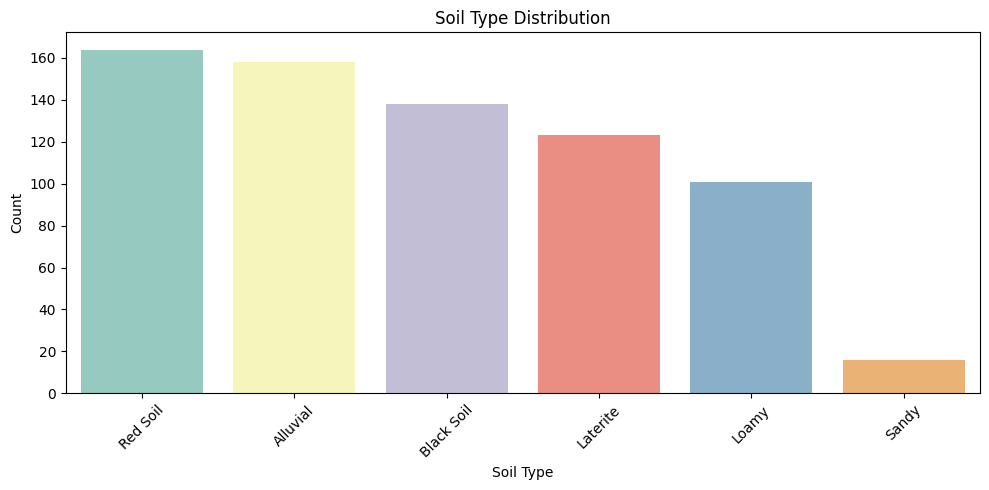

<ipython-input-4-8b0605818da2>:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='pest_name', order=df['pest_name'].value_counts().index, palette='tab20')


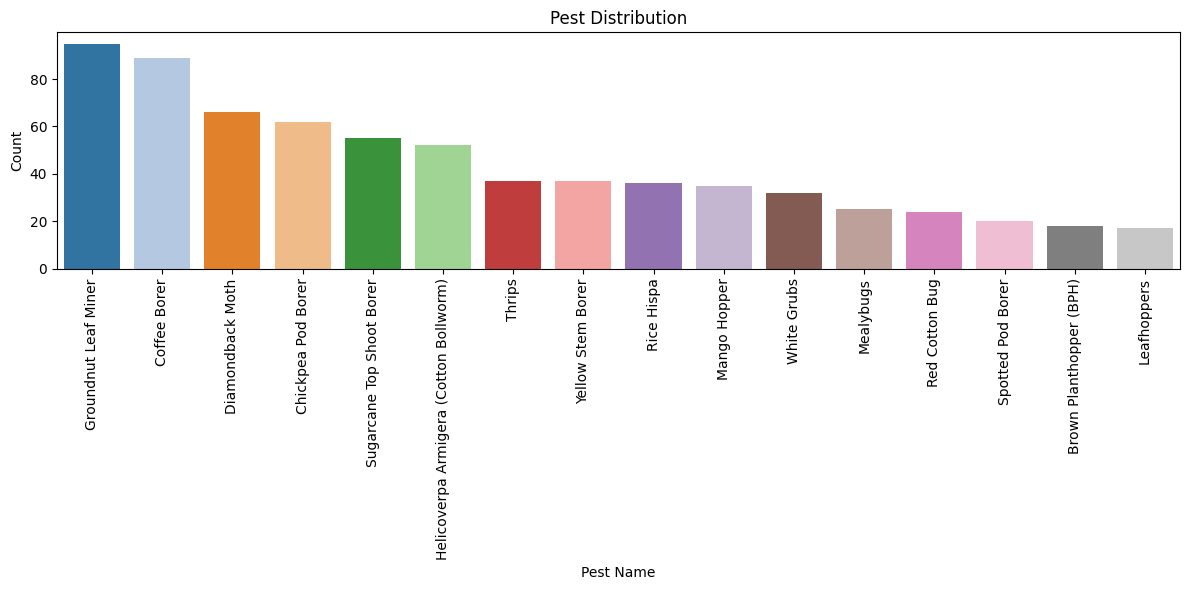

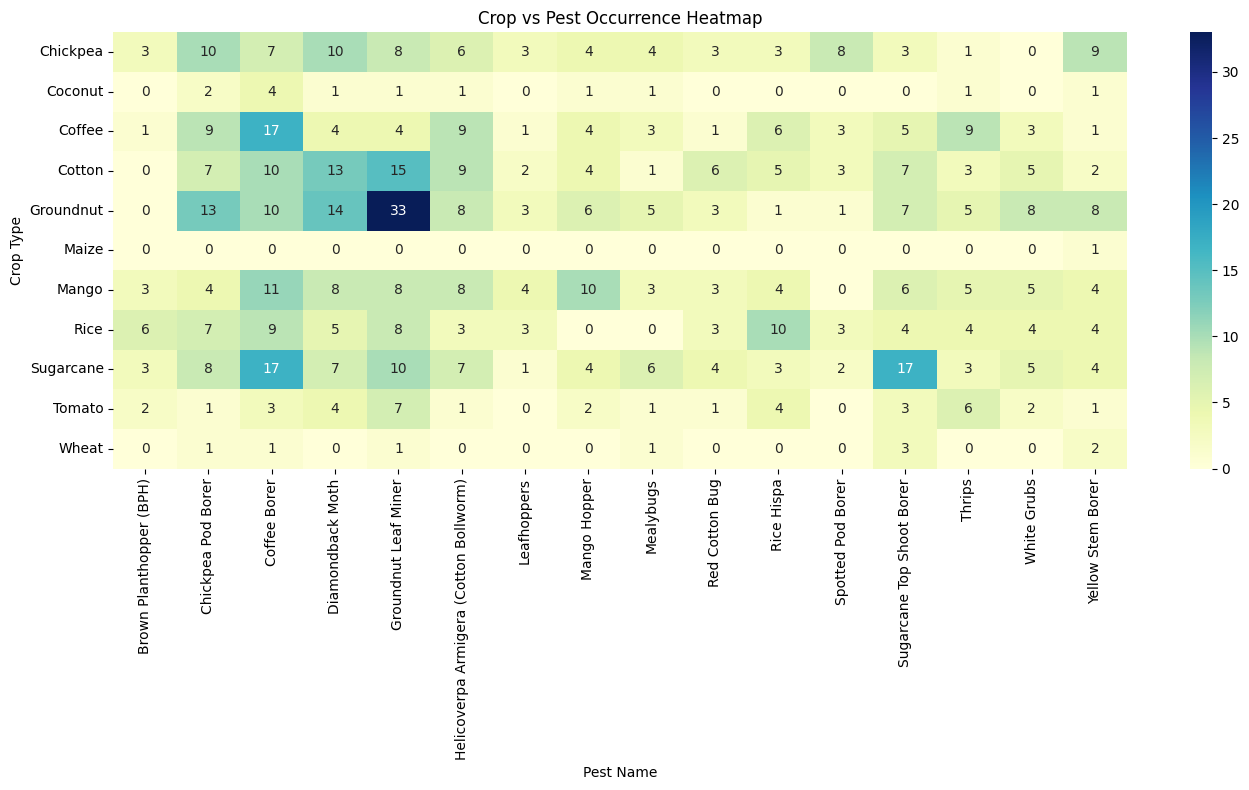

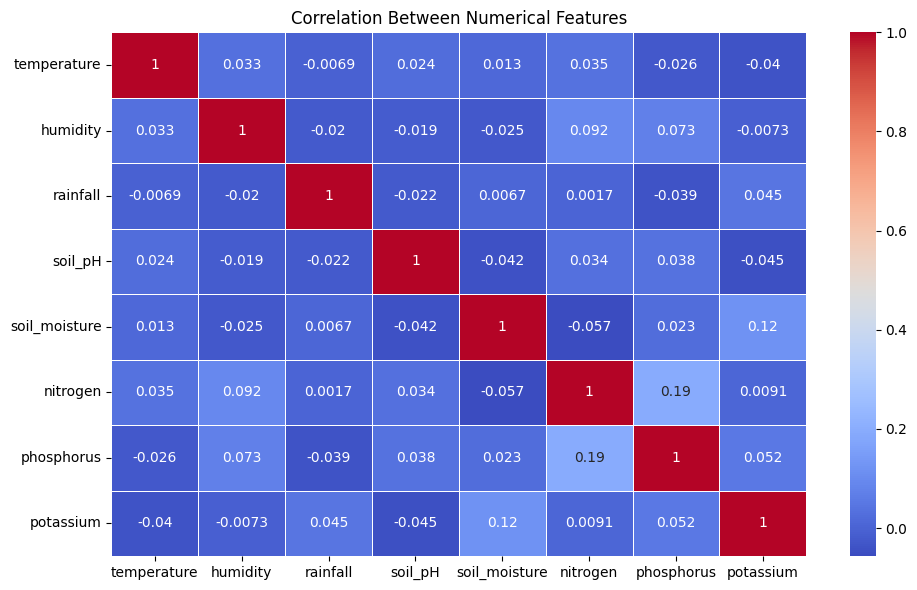

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("/content/Sustainable_Pest_Control_Cleaned.csv")

# Show basic info
print("✅ Dataset Info:")
print(df.info())
print("\n✅ First 5 rows:")
print(df.head())

# ------------------------------
# 1. Soil Type Distribution
# ------------------------------
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='soil_type', order=df['soil_type'].value_counts().index, palette='Set3')
plt.xticks(rotation=45)
plt.title('Soil Type Distribution')
plt.xlabel('Soil Type')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

# ------------------------------
# 2. Pest Distribution
# ------------------------------
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='pest_name', order=df['pest_name'].value_counts().index, palette='tab20')
plt.xticks(rotation=90)
plt.title('Pest Distribution')
plt.xlabel('Pest Name')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

# ------------------------------
# 3. Crop vs. Pest Heatmap
# ------------------------------
crop_pest = pd.crosstab(df['crop_type'], df['pest_name'])
plt.figure(figsize=(14, 8))
sns.heatmap(crop_pest, cmap="YlGnBu", annot=True, fmt='d')
plt.title('Crop vs Pest Occurrence Heatmap')
plt.ylabel('Crop Type')
plt.xlabel('Pest Name')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# ------------------------------
# 4. Correlation Heatmap (Numerical Features)
# ------------------------------
numerical_cols = ['temperature', 'humidity', 'rainfall', 'soil_pH', 'soil_moisture', 'nitrogen', 'phosphorus', 'potassium']
plt.figure(figsize=(10, 6))
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Between Numerical Features')
plt.tight_layout()
plt.show()


<ipython-input-6-1164a846adde>:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='pest_name', y='infestation_severity', palette='viridis')


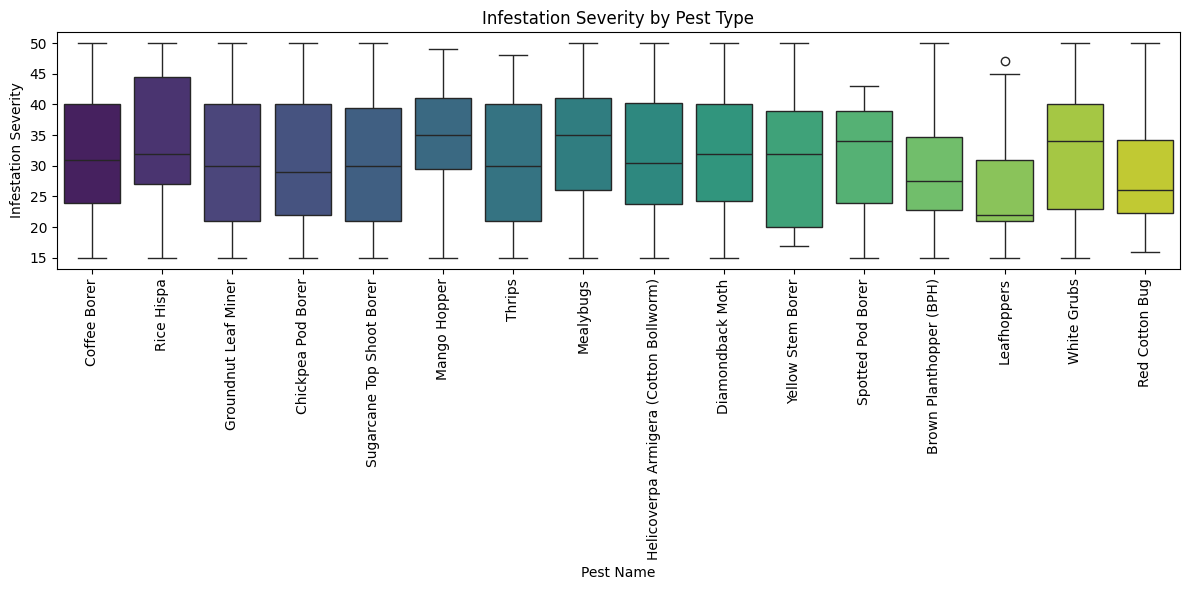

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='pest_name', y='infestation_severity', palette='viridis')
plt.xticks(rotation=90)
plt.title('Infestation Severity by Pest Type')
plt.xlabel('Pest Name')
plt.ylabel('Infestation Severity')
plt.tight_layout()
plt.show()


<ipython-input-7-c75dbf35e509>:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='growth_stage', y='infestation_severity', palette='coolwarm')


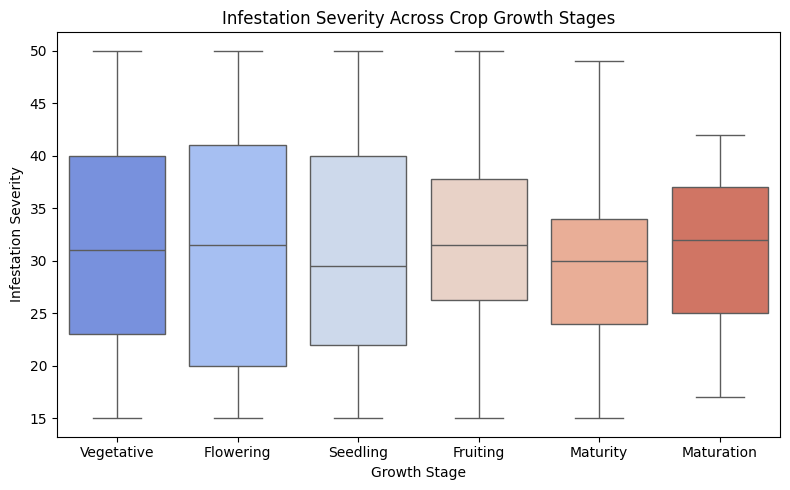

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='growth_stage', y='infestation_severity', palette='coolwarm')
plt.title('Infestation Severity Across Crop Growth Stages')
plt.xlabel('Growth Stage')
plt.ylabel('Infestation Severity')
plt.tight_layout()
plt.show()


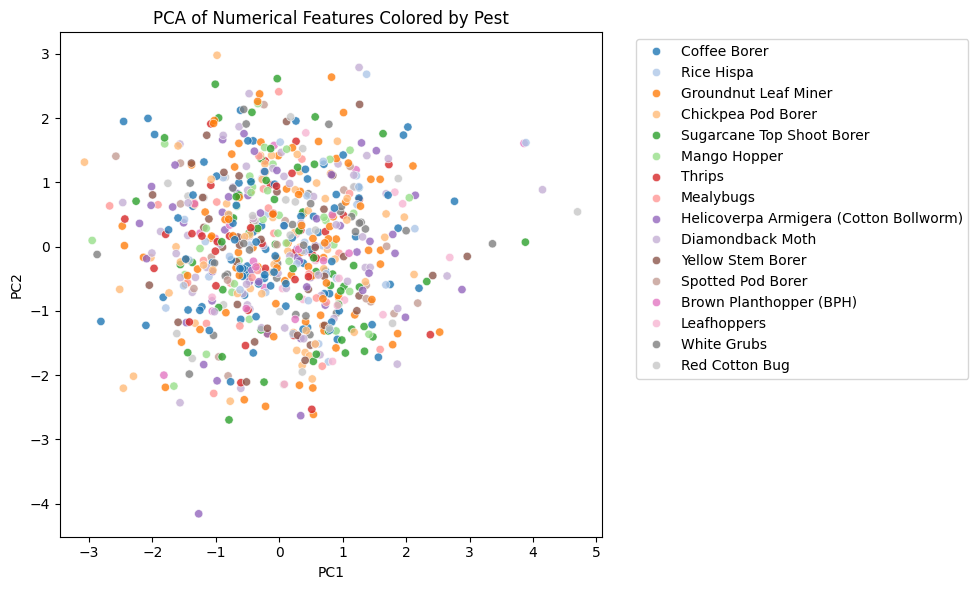

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Select only numerical features
numerical_cols = ['temperature', 'humidity', 'rainfall', 'soil_pH', 'soil_moisture',
                  'infestation_severity', 'nitrogen', 'phosphorus', 'potassium']
X = df[numerical_cols]

# Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA transformation
pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_scaled)

# Create PCA DataFrame
df_pca = pd.DataFrame(data=pca_result, columns=['PC1', 'PC2'])
df_pca['pest_name'] = df['pest_name']

# Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='pest_name', palette='tab20', alpha=0.8)
plt.title('PCA of Numerical Features Colored by Pest')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


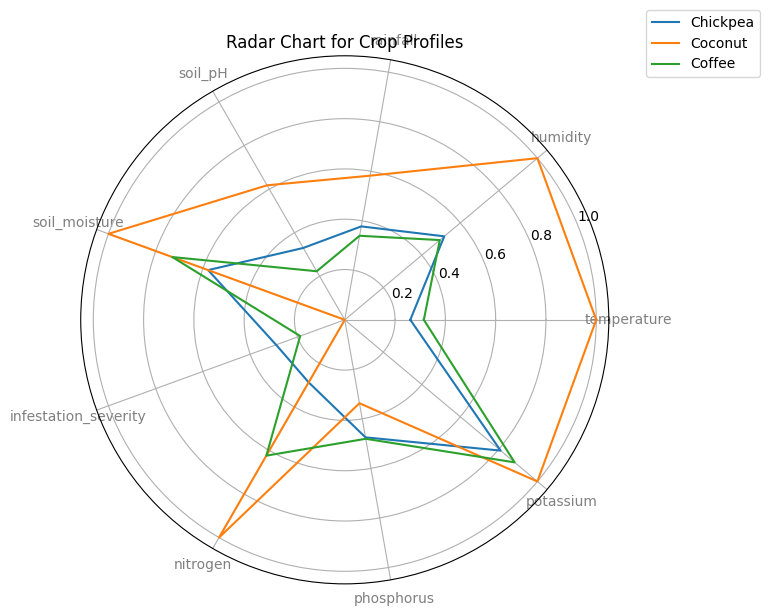

In [ ]:
import numpy as np

# Compute mean values of each crop's numerical features
crop_avg = df.groupby('crop_type')[numerical_cols].mean()

# Radar chart requires data normalization to [0, 1]
crop_norm = (crop_avg - crop_avg.min()) / (crop_avg.max() - crop_avg.min())

# Choose a few crops for visualization
crops_to_plot = crop_norm.head(3)  # You can change this

# Radar chart setup
labels = crop_norm.columns
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]  # loop

plt.figure(figsize=(8, 8))
for crop, row in crops_to_plot.iterrows():
    values = row.tolist()
    values += values[:1]  # loop back
    plt.polar(angles, values, label=crop)

plt.xticks(angles[:-1], labels, color='gray', size=10)
plt.title('Radar Chart for Crop Profiles')
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.show()


In [ ]:
import plotly.express as px

pest_counts = df['pest_name'].value_counts().reset_index()
pest_counts.columns = ['Pest Name', 'Count']

fig = px.pie(pest_counts, values='Count', names='Pest Name', title='Interactive Pest Distribution')
fig.update_traces(textinfo='percent+label')
fig.show()
